In [1]:
## Import required libraries
import os
import re
import json
import statistics
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from openai import OpenAI
from dotenv import load_dotenv

load_dotenv()

client = OpenAI(api_key=os.environ.get("OPENAI_API_KEY"))

MODEL = "gpt-4o-mini"
TEMPERATURE = 0.7

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)
pd.set_option("display.max_colwidth", 120)

print("✅ Setup complete! OpenAI client initialized.")

✅ Setup complete! OpenAI client initialized.


In [2]:
def call_openai(prompt, system_message="You are a helpful assistant.", temperature=TEMPERATURE, max_tokens=None, seed=None):
    """Helper function to call OpenAI API with specified parameters"""
    try:
        params = {
            "model": MODEL,
            "messages": [
                {"role": "system", "content": system_message},
                {"role": "user", "content": prompt},
            ],
            "temperature": temperature,
        }
        if max_tokens:
            params["max_tokens"] = max_tokens
        if seed is not None:
            params["seed"] = seed
        response = client.chat.completions.create(**params)
        return response.choices[0].message.content
    except Exception as e:
        return f"Error: {str(e)}"


def run_n(prompt, n, system_message="You are a helpful assistant.", temperature=TEMPERATURE, max_workers=5):
    """Send the same prompt n times IN PARALLEL and return the n responses."""
    with ThreadPoolExecutor(max_workers=max_workers) as pool:
        futures = [pool.submit(call_openai, prompt, system_message, temperature) for _ in range(n)]
        return [f.result() for f in futures]


def mode_share(items):
    """Share of runs equal to the most common value. None (unusable output) always counts as a miss."""
    if not items:
        return 0.0
    valid = [i for i in items if i is not None]
    if not valid:
        return 0.0
    return Counter(valid).most_common(1)[0][1] / len(items)


def pct(x):
    return round(100 * x, 1)


def show_distinct(responses, max_chars=160):
    """Print each distinct output once, with how often it occurred."""
    counts = Counter(r.strip() for r in responses)
    print(f"{len(counts)} distinct outputs across {len(responses)} runs:")
    for text, c in counts.most_common():
        snippet = text.replace("\n", " ⏎ ")
        if len(snippet) > max_chars:
            snippet = snippet[:max_chars] + "…"
        print(f"  {c:>2}× {snippet}")


ALL_RUNS = []  ## tests logged!!


def test_prompt(task, version, prompt, evaluator, n=15, system_message="You are a helpful assistant.",
                label="", show=True, max_chars=160):
    """Run a prompt n times, score the responses with `evaluator`, log and print the result."""
    responses = run_n(prompt, n, system_message=system_message)
    metrics = evaluator(responses)
    ALL_RUNS.append({"task": task, "version": version, "n": n, "label": label,
                     "prompt": prompt, "system_message": system_message,
                     "metrics": metrics, "responses": responses})
    if show:
        print(f"\n{'=' * 80}\n{task} | {version} | {n} runs {('| ' + label) if label else ''}\n{'=' * 80}")
        show_distinct(responses, max_chars)
        print("\n📊", metrics)
    return responses, metrics


def runs_table(task=None, version=None, label=None):
    """All logged runs (optionally filtered) as a DataFrame."""
    rows = []
    for r in ALL_RUNS:
        if (task and r["task"] != task) or (version and r["version"] != version) or (label and r["label"] != label):
            continue
        rows.append({"Task": r["task"], "Version": r["version"], "Label": r["label"], "Runs": r["n"], **r["metrics"]})
    return pd.DataFrame(rows)


print("✅ Helper functions loaded!")

✅ Helper functions loaded!


# Evaluators

In [3]:
## Sentiment
LABELS = ("Positive", "Negative", "Neutral")


def sentiment_label(text):
    """The single label mentioned in the text, or None if zero or several labels appear."""
    found = [l for l in LABELS if re.search(rf"\b{l}\b", text, re.I)]
    return found[0] if len(found) == 1 else None


def eval_sentiment(responses, expected=None):
    raw = [r.strip() for r in responses]
    labels = [sentiment_label(r) for r in raw]
    m = {
        "unique_outputs": len(set(raw)),
        "consistency_%": pct(mode_share(raw)),               # identical output
        "label_consistency_%": pct(mode_share(labels)),      # same label, even if worded differently
        "format_compliance_%": pct(sum(r in LABELS for r in raw) / len(raw)),  # output is exactly one label
        "errors": sum(r.startswith("Error:") for r in raw),
    }
    if expected:
        m["accuracy_%"] = pct(sum(l == expected for l in labels) / len(raw))
    return m


def parse_json_strict(text):
    """The response is valid JSON as-is (what json.loads in production would need)."""
    try:
        obj = json.loads(text.strip())
        return obj if isinstance(obj, dict) else None
    except json.JSONDecodeError:
        return None


def parse_json_lenient(text):
    """Find a JSON object inside messy output: <json> tags, ```json fences or prose around it."""
    m = re.search(r"<json>(.*?)</json>", text, re.S)
    if m:
        text = m.group(1)
    decoder, pos, found = json.JSONDecoder(), 0, None
    while True:
        i = text.find("{", pos)
        if i == -1:
            return found
        try:
            obj, end = decoder.raw_decode(text, i)
            if isinstance(obj, dict):
                found = obj
            pos = end
        except json.JSONDecodeError:
            pos = i + 1


## Data extraction

def eval_extraction(responses, schema_check=None, expected=None):
    raw = [r.strip() for r in responses]
    parsed = [parse_json_lenient(r) for r in raw]
    canon = [json.dumps(p, sort_keys=True) if p is not None else None for p in parsed]
    n = len(raw)
    m = {
        "unique_outputs": len(set(raw)),
        "consistency_%": pct(mode_share(canon)),                       # identical structured data
        "text_consistency_%": pct(mode_share(raw)),                    # identical raw text
        "parse_rate_%": pct(sum(p is not None for p in parsed) / n),   # JSON found somewhere
        "raw_json_%": pct(sum(parse_json_strict(r) is not None for r in raw) / n),  # whole reply is JSON
        "errors": sum(r.startswith("Error:") for r in raw),
    }
    if schema_check:
        m["schema_valid_%"] = pct(sum(bool(p) and schema_check(p) for p in parsed) / n)
    if expected:
        def score(p):
            if not p:
                return 0.0
            hits = sum(str(p.get(k)).strip().lower() == str(v).strip().lower() for k, v in expected.items())
            return hits / len(expected)
        m["field_accuracy_%"] = pct(sum(score(p) for p in parsed) / n)
    return m


## Product description
LEN_MIN, LEN_MAX = 40, 110


def product_parts(text):
    """Return (headline, features, body_text). Works for JSON (v3) and plain text / markdown (v1, v2)."""
    data = parse_json_strict(text)
    if data:
        headline = str(data.get("headline", "")).strip()
        feats = data.get("features") if isinstance(data.get("features"), list) else []
        body = " ".join([headline, str(data.get("description", "")), *map(str, feats)])
        return headline, feats, body
    lines = [l.strip() for l in text.strip().splitlines() if l.strip()]
    headline = lines[0] if lines else ""
    bullets = [l for l in lines if re.match(r"^([-*•]|\d+\.)\s", l)]
    return headline, bullets, text


def check_product(text, facts_text, price):
    headline, feats, body = product_parts(text)
    words = len(re.findall(r"\b\w[\w'-]*\b", body))
    invented = sorted(set(re.findall(r"\d+(?:\.\d+)?", body)) - set(re.findall(r"\d+(?:\.\d+)?", facts_text)))
    checks = {
        "headline_ok": 0 < len(headline.split()) <= 10 and not headline.startswith(("#", "*")),
        "three_features": len(feats) == 3,
        "length_ok": LEN_MIN <= words <= LEN_MAX,
        "price_ok": price in text,
        "no_invented_numbers": not invented,
    }
    return checks, words, invented


def eval_product(responses, facts_text, price):
    results = [check_product(r, facts_text, price) for r in responses]
    checks = [c for c, _, _ in results]
    words = [w for _, w, _ in results]
    n = len(responses)
    m = {
        "unique_outputs": len(set(r.strip() for r in responses)),
        "consistency_%": pct(sum(all(c.values()) for c in checks) / n),
        "words_mean": round(statistics.mean(words), 1),
        "words_cv_%": round(100 * statistics.pstdev(words) / statistics.mean(words), 1) if statistics.mean(words) else 0,
        "errors": sum(r.startswith("Error:") for r in responses),
    }
    for key in checks[0]:
        m[f"{key}_%"] = pct(sum(c[key] for c in checks) / n)
    return m


print("✅ Evaluators loaded!")

✅ Evaluators loaded!


In [4]:
SENTIMENT_MESSAGE = "I love this product! It's exactly what I needed."
EXTRACTION_FEEDBACK = "I ordered item #12345 on March 15th. The delivery was fast but the packaging was damaged."
MOUSE_PRICE = "$29.99"

sentiment_prompt_v1 = """
Classify this customer message: "I love this product! It's exactly what I needed."
"""

product_prompt_v1 = """
Create a product description for a wireless mouse that costs $29.99.
"""

extraction_prompt_v1 = """
Extract information from this customer feedback: "I ordered item #12345 on March 15th. The delivery was fast but the packaging was damaged."
"""

for name, prompt in [("Sentiment Analysis", sentiment_prompt_v1),
                     ("Product Description", product_prompt_v1),
                     ("Data Extraction", extraction_prompt_v1)]:
    print(f"\n{'=' * 60}\n📝 {name} Result:\n{'=' * 60}")
    print(call_openai(prompt))


📝 Sentiment Analysis Result:
This customer message can be classified as **Positive Feedback** or **Customer Satisfaction**.

📝 Product Description Result:
**Product Description: Wireless Precision Mouse - $29.99**

Upgrade your workspace with our sleek and versatile Wireless Precision Mouse, designed to enhance your productivity and comfort. Priced at just $29.99, this mouse combines cutting-edge technology with modern aesthetics, making it the perfect accessory for both home and office use.

**Key Features:**

- **Wireless Freedom**: Say goodbye to tangled cords! Our wireless technology provides a seamless connection up to 33 feet away, ensuring you can work comfortably without being tethered to your computer.

- **Ergonomic Design**: The contoured shape of the mouse fits comfortably in your hand, reducing strain during long hours of use. Whether you’re navigating spreadsheets or browsing the web, enjoy a natural grip that promotes better posture.

- **High Precision Tracking**: Equi

In [8]:
# Scorers for the base inputs (same rules for v1, v2 and v3)
EXPECTED_BASE_EXTRACTION = {"order_id": "12345", "order_date": "03-15",
                            "delivery_speed": "fast", "packaging_condition": "damaged"}

score_sentiment = lambda rs: eval_sentiment(rs, expected="Positive")
score_extraction = lambda rs: eval_extraction(rs, expected=EXPECTED_BASE_EXTRACTION)
# v1 and v2 only receive "wireless mouse, $29.99", so any other number in the output was invented
score_product_v1 = lambda rs: eval_product(rs, facts_text="wireless mouse $29.99", price=MOUSE_PRICE)

In [9]:
SENTIMENT_MESSAGE = "I love this product! It's exactly what I needed."
EXTRACTION_FEEDBACK = "I ordered item #12345 on March 15th. The delivery was fast but the packaging was damaged."
MOUSE_PRICE = "$29.99"

sentiment_prompt_v1 = """
Classify this customer message: "I love this product! It's exactly what I needed."
"""

product_prompt_v1 = """
Create a product description for a wireless mouse that costs $29.99.
"""

extraction_prompt_v1 = """
Extract information from this customer feedback: "I ordered item #12345 on March 15th. The delivery was fast but the packaging was damaged."
"""

for name, prompt in [("Sentiment Analysis", sentiment_prompt_v1),
                     ("Product Description", product_prompt_v1),
                     ("Data Extraction", extraction_prompt_v1)]:
    print(f"\n{'=' * 60}\n📝 {name} Result:\n{'=' * 60}")
    print(call_openai(prompt))


📝 Sentiment Analysis Result:
The customer message can be classified as "Positive Feedback" or "Satisfaction."

📝 Product Description Result:
**Product Name:** SwiftClick Wireless Mouse

**Price:** $29.99

**Product Description:**

Elevate your computing experience with the SwiftClick Wireless Mouse, designed to provide seamless navigation and maximum comfort for both work and play. Engineered with precision and convenience in mind, this sleek and stylish mouse is the perfect companion for your laptop or desktop.

**Key Features:**

- **Wireless Freedom:** Say goodbye to tangled cords! The SwiftClick features a reliable 2.4GHz wireless connection, allowing you to move freely without the hassle of wires. Enjoy a clutter-free workspace and a range of up to 33 feet.

- **Ergonomic Design:** Crafted for comfort, our mouse fits perfectly in your hand, reducing strain during long hours of use. The contoured shape and textured grip ensure you can navigate with ease and precision, whether you'

# Diagnosing failures

In [10]:
for task, prompt, scorer in [("Sentiment", sentiment_prompt_v1, score_sentiment),
                             ("Product", product_prompt_v1, score_product_v1),
                             ("Extraction", extraction_prompt_v1, score_extraction)]:
    test_prompt(task, "v1", prompt, scorer, n=5, label="diagnosis")


Sentiment | v1 | 5 runs | diagnosis
5 distinct outputs across 5 runs:
   1× The customer message can be classified as positive feedback or a positive review.
   1× This customer message can be classified as "Positive Feedback" or "Satisfaction."
   1× This customer message can be classified as **positive feedback** or **customer satisfaction**.
   1× The customer message can be classified as "Positive Feedback" or "Customer Praise."
   1× The customer message can be classified as **Positive Feedback** or **Satisfaction**.

📊 {'unique_outputs': 5, 'consistency_%': 20.0, 'label_consistency_%': 100.0, 'format_compliance_%': 0.0, 'errors': 0, 'accuracy_%': 100.0}

Product | v1 | 5 runs | diagnosis
5 distinct outputs across 5 runs:
   1× **Product Description: Wireless Freedom Mouse** ⏎  ⏎ Elevate your computing experience with our Wireless Freedom Mouse, designed to provide seamless functionali…
   1× **Product Description: Wireless Precision Mouse - $29.99** ⏎  ⏎ Upgrade your computing e

## Each prompt 10 times

In [11]:
for task, prompt, scorer in [("Sentiment", sentiment_prompt_v1, score_sentiment),
                             ("Product", product_prompt_v1, score_product_v1),
                             ("Extraction", extraction_prompt_v1, score_extraction)]:
    test_prompt(task, "v1", prompt, scorer, n=10, label="diagnosis")


Sentiment | v1 | 10 runs | diagnosis
7 distinct outputs across 10 runs:
   2× The customer message can be classified as **positive feedback** or **satisfaction**.
   2× The customer message can be classified as **Positive Feedback** or **Customer Satisfaction**.
   2× The customer message can be classified as "Positive Feedback" or "Satisfaction."
   1× The customer message can be classified as **positive feedback** or **customer satisfaction**.
   1× The customer message can be classified as **Positive Feedback**.
   1× The customer message can be classified as "Positive Feedback" or "Customer Satisfaction."
   1× This customer message can be classified as "Positive Feedback" or "Customer Satisfaction."

📊 {'unique_outputs': 7, 'consistency_%': 20.0, 'label_consistency_%': 100.0, 'format_compliance_%': 0.0, 'errors': 0, 'accuracy_%': 100.0}

Product | v1 | 10 runs | diagnosis
10 distinct outputs across 10 runs:
   1× **Product Description: Wireless Ergonomic Mouse - $29.99** ⏎  ⏎ Ele

## 15 times


In [12]:
for task, prompt, scorer in [("Sentiment", sentiment_prompt_v1, score_sentiment),
                             ("Product", product_prompt_v1, score_product_v1),
                             ("Extraction", extraction_prompt_v1, score_extraction)]:
    test_prompt(task, "v1", prompt, scorer, n=15, label="diagnosis")


Sentiment | v1 | 15 runs | diagnosis
9 distinct outputs across 15 runs:
   3× The customer message can be classified as "Positive Feedback" or "Customer Satisfaction."
   3× The customer message can be classified as **positive feedback** or **customer satisfaction**.
   2× This customer message can be classified as "Positive Feedback" or "Customer Satisfaction."
   2× The customer message can be classified as positive feedback or a positive review.
   1× This customer message can be classified as **positive feedback** or **satisfaction**.
   1× This customer message can be classified as **Positive Feedback** or **Customer Praise**.
   1× The customer message can be classified as **Positive Feedback** or **Customer Satisfaction**.
   1× The customer message can be classified as **Positive Feedback**.
   1× The customer message can be classified as "Positive Feedback" or "Satisfaction."

📊 {'unique_outputs': 9, 'consistency_%': 20.0, 'label_consistency_%': 100.0, 'format_compliance_%': 

In [ ]:
# Consistancy analysis
diag = runs_table(version="v1", label="diagnosis")
for task in ["Sentiment", "Product", "Extraction"]:
    print(f"\n### {task} — v1 across 5 / 10 / 15 runs")
    display(diag[diag.Task == task].dropna(axis=1, how="all"))


### Sentiment — v1 across 5 / 10 / 15 runs


,Task,Version,Label,Runs,unique_outputs,consistency_%,label_consistency_%,format_compliance_%,errors,accuracy_%
0,Sentiment,v1,diagnosis,5,5,20.0,100.0,0.0,0,100.0
3,Sentiment,v1,diagnosis,10,7,20.0,100.0,0.0,0,100.0
6,Sentiment,v1,diagnosis,15,9,20.0,100.0,0.0,0,100.0



### Product — v1 across 5 / 10 / 15 runs


,Task,Version,Label,Runs,unique_outputs,consistency_%,errors,words_mean,words_cv_%,headline_ok_%,three_features_%,length_ok_%,price_ok_%,no_invented_numbers_%
1,Product,v1,diagnosis,5,5,0.0,0,291.6,8.0,0.0,0.0,0.0,100.0,20.0
4,Product,v1,diagnosis,10,10,0.0,0,298.7,9.0,0.0,0.0,0.0,100.0,0.0
7,Product,v1,diagnosis,15,15,0.0,0,301.1,6.4,0.0,0.0,0.0,100.0,0.0



### Extraction — v1 across 5 / 10 / 15 runs


,Task,Version,Label,Runs,unique_outputs,consistency_%,errors,text_consistency_%,parse_rate_%,raw_json_%,field_accuracy_%
2,Extraction,v1,diagnosis,5,3,0.0,0,60.0,0.0,0.0,0.0
5,Extraction,v1,diagnosis,10,9,0.0,0,20.0,0.0,0.0,0.0
8,Extraction,v1,diagnosis,15,8,0.0,0,40.0,0.0,0.0,0.0


In [14]:
# Documented failure patterns (also written into failure_analysis_report.md)
FAILURE_PATTERNS = {
    "Sentiment": [
        ("No label set given", "The model invents its own categories ('Positive Feedback', 'Customer Satisfaction', 'customer compliment') instead of Positive/Negative/Neutral."),
        ("Sentence instead of a label", "Every answer is a full sentence ('This customer message can be classified as…'), so nothing can be matched programmatically."),
        ("Hedging with two labels", "Many runs give two answers ('X or Y'), so there is no single decision."),
        ("Formatting drift", "Bold, quotes and capitalisation change from run to run, so identical meaning ≠ identical output."),
    ],
    "Product": [
        ("Every run unique", "No two descriptions are the same and length varies widely; there is no defined structure or length."),
        ("Invented specifications", "With only a name and price, the model fills gaps with made-up facts (range in feet, DPI levels, months of battery) that contradict each other across runs — e.g. battery 'included' vs 'not included'. Publishing this would be false advertising."),
        ("Too long and markdown-heavy", "Typical output is several hundred words with headings, bold and 5–7 bullets — far too long for a product page block."),
        ("Inconsistent naming", "The product gets a different invented name almost every run ('Precision', 'Freedom', 'Ergonomic', 'Comfort')."),
    ],
    "Extraction": [
        ("Not machine-readable", "Output is a markdown bullet list with a chatty preamble, so a downstream system cannot parse it."),
        ("No schema", "Field names are chosen by the model ('Order Number' vs 'order_number'), so they can change between runs or inputs."),
        ("Unnormalised / invented values", "'#12345' vs '12345', 'March 15th' kept as text; when asked for a date format the model invented a year (2023) that is not in the feedback."),
        ("Looks stable on easy input", "On this short, explicit sentence the content is fairly stable — the failure is format, not understanding. Harder inputs (Part 5) expose content errors."),
    ],
}

pd.DataFrame([{"Task": t, "Pattern": p, "Evidence": e} for t, rows in FAILURE_PATTERNS.items() for p, e in rows])

,Task,Pattern,Evidence
0,Sentiment,No label set given,"The model invents its own categories ('Positive Feedback', 'Customer Satisfaction', 'customer compliment') instead o..."
1,Sentiment,Sentence instead of a label,"Every answer is a full sentence ('This customer message can be classified as…'), so nothing can be matched programma..."
2,Sentiment,Hedging with two labels,"Many runs give two answers ('X or Y'), so there is no single decision."
3,Sentiment,Formatting drift,"Bold, quotes and capitalisation change from run to run, so identical meaning ≠ identical output."
4,Product,Every run unique,No two descriptions are the same and length varies widely; there is no defined structure or length.
5,Product,Invented specifications,"With only a name and price, the model fills gaps with made-up facts (range in feet, DPI levels, months of battery) t..."
6,Product,Too long and markdown-heavy,"Typical output is several hundred words with headings, bold and 5–7 bullets — far too long for a product page block."
7,Product,Inconsistent naming,"The product gets a different invented name almost every run ('Precision', 'Freedom', 'Ergonomic', 'Comfort')."
8,Extraction,Not machine-readable,"Output is a markdown bullet list with a chatty preamble, so a downstream system cannot parse it."
9,Extraction,No schema,"Field names are chosen by the model ('Order Number' vs 'order_number'), so they can change between runs or inputs."


# Part 3, iteration 1

In [15]:
sentiment_template_v2 = """Classify the sentiment of the customer message below.

Rules:
- Answer with exactly one word: Positive, Negative, or Neutral.
- No punctuation, no explanation, no extra text.

Customer message: "<<MESSAGE>>"
Sentiment:"""

sentiment_prompt_v2 = sentiment_template_v2.replace("<<MESSAGE>>", SENTIMENT_MESSAGE)
_ = test_prompt("Sentiment", "v2", sentiment_prompt_v2, score_sentiment, n=15, label="iteration1")


Sentiment | v2 | 15 runs | iteration1
1 distinct outputs across 15 runs:
  15× Positive

📊 {'unique_outputs': 1, 'consistency_%': 100.0, 'label_consistency_%': 100.0, 'format_compliance_%': 100.0, 'errors': 0, 'accuracy_%': 100.0}


In [16]:
product_template_v2 = """Write a product description for an online store.

Product: <<PRODUCT>>
Price: <<PRICE>>

Requirements:
- Line 1: a headline of at most 8 words.
- Then one short paragraph of 2 sentences.
- Then exactly 3 bullet points, each starting with "- " and at most 12 words.
- Total length: 60-100 words.
- Tone: friendly and clear. Avoid hype words like "revolutionary" or "ultimate".
- Mention the price exactly once, written as <<PRICE>>.
- Plain text only: no markdown headings, no bold."""

product_prompt_v2 = product_template_v2.replace("<<PRODUCT>>", "Wireless mouse").replace("<<PRICE>>", MOUSE_PRICE)
_ = test_prompt("Product", "v2", product_prompt_v2, score_product_v1, n=15, label="iteration1", max_chars=200)


Product | v2 | 15 runs | iteration1
15 distinct outputs across 15 runs:
   1× Effortless Control with Our Wireless Mouse ⏎  ⏎ Experience smooth navigation and comfort with this sleek wireless mouse. Designed for everyday use, it connects easily to your devices and fits perfectl…
   1× Effortless Navigation with Our Wireless Mouse ⏎  ⏎ Experience smooth and reliable control with our wireless mouse. Priced at $29.99, it’s perfect for work or play, providing comfort and convenience. ⏎…
   1× Effortless Control with Our Wireless Mouse ⏎  ⏎ Experience smooth navigation and comfort with our wireless mouse. Designed for everyday use, it provides reliable connectivity and a sleek design at an …
   1× Effortless Control with Our Wireless Mouse   ⏎  ⏎ Experience smooth navigation and comfort with our wireless mouse, designed for everyday use. At just $29.99, it’s the perfect companion for your home …
   1× Effortless Navigation with Our Wireless Mouse ⏎  ⏎ Experience seamless scrolling and prec

In [17]:
extraction_template_v2 = """Extract information from the customer feedback below.

Return ONLY a JSON object with these keys:
- "order_id": string, digits only, or null
- "order_date": "YYYY-MM-DD" if the year is stated, "MM-DD" if not, or null. Never guess a year.
- "delivery_speed": short lowercase word describing delivery speed, or null
- "packaging_condition": short lowercase word describing the packaging, or null
- "issues": list of short descriptions of each problem mentioned
- "sentiment": "positive", "negative", or "neutral"

Use null for anything that is not mentioned.

Customer feedback: "<<FEEDBACK>>\""""

extraction_prompt_v2 = extraction_template_v2.replace("<<FEEDBACK>>", EXTRACTION_FEEDBACK)
V2_KEYS = {"order_id", "order_date", "delivery_speed", "packaging_condition", "issues", "sentiment"}
score_extraction_v2 = lambda rs: eval_extraction(rs, schema_check=lambda p: set(p) == V2_KEYS,
                                                 expected=EXPECTED_BASE_EXTRACTION)
_ = test_prompt("Extraction", "v2", extraction_prompt_v2, score_extraction_v2, n=15, label="iteration1")


Extraction | v2 | 15 runs | iteration1
3 distinct outputs across 15 runs:
   8× ```json ⏎ { ⏎   "order_id": "12345", ⏎   "order_date": "03-15", ⏎   "delivery_speed": "fast", ⏎   "packaging_condition": "damaged", ⏎   "issues": ["packaging wa…
   4× ```json ⏎ { ⏎   "order_id": "12345", ⏎   "order_date": "03-15", ⏎   "delivery_speed": "fast", ⏎   "packaging_condition": "damaged", ⏎   "issues": ["packaging da…
   3× ```json ⏎ { ⏎   "order_id": "12345", ⏎   "order_date": "03-15", ⏎   "delivery_speed": "fast", ⏎   "packaging_condition": "damaged", ⏎   "issues": [ ⏎     "packa…

📊 {'unique_outputs': 3, 'consistency_%': 73.3, 'text_consistency_%': 53.3, 'parse_rate_%': 100.0, 'raw_json_%': 0.0, 'errors': 0, 'schema_valid_%': 100.0, 'field_accuracy_%': 100.0}


In [18]:
# Checkpoint: v1 (15 runs) vs v2 (15 runs)
cmp = pd.concat([runs_table(version="v1", label="diagnosis").query("Runs == 15"),
                 runs_table(version="v2")])
for task in ["Sentiment", "Product", "Extraction"]:
    print(f"\n### {task}: v1 vs v2")
    display(cmp[cmp.Task == task].dropna(axis=1, how="all"))


### Sentiment: v1 vs v2


,Task,Version,Label,Runs,unique_outputs,consistency_%,label_consistency_%,format_compliance_%,errors,accuracy_%
6,Sentiment,v1,diagnosis,15,9,20.0,100.0,0.0,0,100.0
0,Sentiment,v2,iteration1,15,1,100.0,100.0,100.0,0,100.0



### Product: v1 vs v2


,Task,Version,Label,Runs,unique_outputs,consistency_%,errors,words_mean,words_cv_%,headline_ok_%,three_features_%,length_ok_%,price_ok_%,no_invented_numbers_%
7,Product,v1,diagnosis,15,15,0.0,0,301.1,6.4,0.0,0.0,0.0,100.0,0.0
1,Product,v2,iteration1,15,15,80.0,0,49.1,7.2,100.0,100.0,100.0,80.0,100.0



### Extraction: v1 vs v2


,Task,Version,Label,Runs,unique_outputs,consistency_%,errors,text_consistency_%,parse_rate_%,raw_json_%,field_accuracy_%,schema_valid_%
8,Extraction,v1,diagnosis,15,8,0.0,0,40.0,0.0,0.0,0.0,NaN
2,Extraction,v2,iteration1,15,3,73.3,0,53.3,100.0,0.0,100.0,100.0


# Iteration 2

In [19]:
SENTIMENT_SYSTEM_V3 = "You are a sentiment classifier for TechFlow Solutions customer support. You reply with a single label only."

sentiment_template_v3 = """Classify the sentiment of customer messages as Positive, Negative, or Neutral.

Definitions:
- Positive: the customer is satisfied, grateful, or praising.
- Negative: the customer complains, is frustrated, or reports a problem (even if polite or sarcastic).
- Neutral: a question, request, or factual statement with no clear emotion.
If a message contains both praise and a problem, label the problem: Negative.

Reply with the label only.

Message: "The checkout page keeps crashing and I've lost my cart twice."
Sentiment: Negative

Message: "Can you tell me when the blue version will be back in stock?"
Sentiment: Neutral

Message: "Setup took two minutes and it works perfectly. Great job!"
Sentiment: Positive

Message: "Delivery was quick, but the charger stopped working after a day."
Sentiment: Negative

Message: "<<MESSAGE>>"
Sentiment:"""

sentiment_prompt_v3 = sentiment_template_v3.replace("<<MESSAGE>>", SENTIMENT_MESSAGE)
_ = test_prompt("Sentiment", "v3", sentiment_prompt_v3, score_sentiment, n=15,
                system_message=SENTIMENT_SYSTEM_V3, label="iteration2")


Sentiment | v3 | 15 runs | iteration2
1 distinct outputs across 15 runs:
  15× Positive

📊 {'unique_outputs': 1, 'consistency_%': 100.0, 'label_consistency_%': 100.0, 'format_compliance_%': 100.0, 'errors': 0, 'accuracy_%': 100.0}


In [20]:
EXTRACTION_SYSTEM_V3 = "You extract structured data from customer feedback for TechFlow Solutions' support system. You never invent information that is not in the feedback."

extraction_template_v3 = """Extract structured data from the customer feedback.

First think step by step inside <reasoning> tags:
1. Order ID: find any order or item number. Keep digits only. null if none.
2. Order date: convert to YYYY-MM-DD if the year is stated, MM-DD if not, null if no date. Never guess a year.
3. For delivery, packaging and product, pick the allowed value that fits, or "not_mentioned".
4. Issues: list every problem as a code from the allowed list ([] if none).
5. Sentiment and the action the customer is asking for.

Then give the final answer inside <json> tags, matching this schema exactly:
{
  "order_id": string or null,
  "order_date": string or null,
  "delivery_speed": "fast" | "on_time" | "slow" | "not_mentioned",
  "packaging_condition": "intact" | "damaged" | "not_mentioned",
  "product_condition": "working" | "damaged" | "defective" | "not_mentioned",
  "issues": list of codes from ["damaged_packaging", "damaged_product", "defective_product", "late_delivery", "wrong_item", "missing_item", "billing_problem", "other"],
  "sentiment": "positive" | "negative" | "mixed" | "neutral",
  "action_requested": "refund" | "replacement" | "information" | "none"
}
Use "mixed" when the feedback contains both clear praise and a clear problem.
"damaged" means physical damage; "defective" means it does not work.

Example
Feedback: "Ordered a keyboard (order 4471) on 2025-11-20. It took 3 weeks to arrive and two keys were snapped off, so I'd like a replacement."
<reasoning>
1. Order ID: "order 4471" -> 4471.
2. Date: 2025-11-20, year stated -> 2025-11-20.
3. Delivery: "3 weeks to arrive" -> slow. Packaging: not mentioned -> not_mentioned. Product: keys snapped off is physical damage -> damaged.
4. Issues: late_delivery, damaged_product.
5. Sentiment: only complaints -> negative. Action: asks for a replacement -> replacement.
</reasoning>
<json>{"order_id": "4471", "order_date": "2025-11-20", "delivery_speed": "slow", "packaging_condition": "not_mentioned", "product_condition": "damaged", "issues": ["late_delivery", "damaged_product"], "sentiment": "negative", "action_requested": "replacement"}</json>

Feedback: "<<FEEDBACK>>\""""

ENUMS_V3 = {
    "delivery_speed": {"fast", "on_time", "slow", "not_mentioned"},
    "packaging_condition": {"intact", "damaged", "not_mentioned"},
    "product_condition": {"working", "damaged", "defective", "not_mentioned"},
    "sentiment": {"positive", "negative", "mixed", "neutral"},
    "action_requested": {"refund", "replacement", "information", "none"},
}
ISSUE_CODES = {"damaged_packaging", "damaged_product", "defective_product", "late_delivery",
               "wrong_item", "missing_item", "billing_problem", "other"}
V3_KEYS = set(ENUMS_V3) | {"order_id", "order_date", "issues"}


def valid_extraction_v3(p):
    """Production schema check: exact keys, allowed values only, normalised ID and date."""
    if set(p) != V3_KEYS:
        return False
    if any(p[k] not in allowed for k, allowed in ENUMS_V3.items()):
        return False
    if p["order_id"] is not None and not re.fullmatch(r"\d+", str(p["order_id"])):
        return False
    if p["order_date"] is not None and not re.fullmatch(r"(\d{4}-)?\d{2}-\d{2}", str(p["order_date"])):
        return False
    return isinstance(p["issues"], list) and set(p["issues"]) <= ISSUE_CODES


score_extraction_v3 = lambda rs: eval_extraction(rs, schema_check=valid_extraction_v3,
                                                 expected=EXPECTED_BASE_EXTRACTION)

extraction_prompt_v3 = extraction_template_v3.replace("<<FEEDBACK>>", EXTRACTION_FEEDBACK)
responses, _ = test_prompt("Extraction", "v3", extraction_prompt_v3, score_extraction_v3, n=15,
                           system_message=EXTRACTION_SYSTEM_V3, label="iteration2", max_chars=120)

print("\nExample of one full CoT response:\n")
print(responses[0])
print("\nParsed JSON values across runs:")
show_distinct([json.dumps(parse_json_lenient(r), sort_keys=True) for r in responses], max_chars=300)


Extraction | v3 | 15 runs | iteration2
15 distinct outputs across 15 runs:
   1× <reasoning> ⏎ 1. Order ID: "item #12345" -> 12345. ⏎ 2. Date: "March 15th" -> 03-15 (no year stated). ⏎ 3. Delivery: "de…
   1× <reasoning> ⏎ 1. Order ID: "item #12345" -> 12345. ⏎ 2. Date: "March 15th" -> 03-15 (year not stated). ⏎ 3. Delivery: "T…
   1× <reasoning> ⏎ 1. Order ID: "item #12345" -> 12345. ⏎ 2. Date: March 15th, year not stated -> 03-15. ⏎ 3. Delivery: "The …
   1× <reasoning> ⏎ 1. Order ID: "item #12345" -> 12345. ⏎ 2. Date: "March 15th" -> 03-15. ⏎ 3. Delivery: "the delivery was fa…
   1× <reasoning> ⏎ 1. Order ID: "item #12345" -> 12345. ⏎ 2. Date: "March 15th" -> 03-15. ⏎ 3. Delivery: "The delivery was fa…
   1× <reasoning> ⏎ 1. Order ID: "item #12345" -> 12345. ⏎ 2. Date: "March 15th" does not state a year -> 03-15. ⏎ 3. Delivery…
   1× <reasoning> ⏎ 1. Order ID: "item #12345" -> 12345. ⏎ 2. Date: "March 15th" -> 03-15. ⏎ 3. Delivery: "The delivery was fa…
   1× <reasoning> ⏎ 1. Order

# product description v3

In [21]:
PRODUCT_SYSTEM_V3 = "You are a copywriter for TechFlow Solutions' web shop. You write accurate, concise product copy and never invent specifications."

product_template_v3 = """Write a product description using ONLY the facts provided.
Do not invent specifications, numbers, colours, materials or compatibility claims that are not in the facts.

Return valid JSON only (no code fences, no extra text) with exactly these keys:
- "headline": at most 8 words
- "description": 2 sentences, 25-45 words in total
- "features": a list of exactly 3 strings, each at most 10 words, each based on one fact
- "price": the price exactly as given

Example 1
Facts: product=USB-C Charging Cable; price=$12.99; length 2 m; braided nylon; supports 60W fast charging
Output: {"headline": "Braided USB-C Cable Built to Last", "description": "This 2 m USB-C cable gives you room to charge from the couch or the desk. Its braided nylon jacket resists fraying, and 60W support charges laptops and phones quickly.", "features": ["2 m length for flexible placement", "Braided nylon jacket resists fraying", "Supports 60W fast charging"], "price": "$12.99"}

Example 2
Facts: product=Portable Bluetooth Speaker; price=$39.99; waterproof (IPX7); 12-hour battery; Bluetooth 5.0
Output: {"headline": "Waterproof Sound for Every Adventure", "description": "Take your music to the beach, the pool or the trail. IPX7 waterproofing and a 12-hour battery keep the music going all day, rain or shine.", "features": ["IPX7 waterproof rating", "Up to 12 hours of playtime", "Stable Bluetooth 5.0 connection"], "price": "$39.99"}

Facts: <<FACTS>>
Output:"""

MOUSE_FACTS = ("product=Wireless Mouse; price=$29.99; 2.4 GHz USB receiver; "
               "up to 12 months battery on one AA battery; silent clicks; ambidextrous design")
score_product_v3 = lambda rs: eval_product(rs, facts_text=MOUSE_FACTS, price=MOUSE_PRICE)

product_prompt_v3 = product_template_v3.replace("<<FACTS>>", MOUSE_FACTS)
_ = test_prompt("Product", "v3", product_prompt_v3, score_product_v3, n=15,
                system_message=PRODUCT_SYSTEM_V3, label="iteration2", max_chars=200)


Product | v3 | 15 runs | iteration2
15 distinct outputs across 15 runs:
   1× {"headline": "Silent Ambidextrous Wireless Mouse", "description": "This wireless mouse features a 2.4 GHz USB receiver for a reliable connection. Enjoy up to 12 months of battery life on a single AA b…
   1× {"headline": "Silent Wireless Mouse for All Users", "description": "This wireless mouse features an ambidextrous design, making it comfortable for both left and right-handed users. With silent clicks …
   1× {"headline": "Silent and Versatile Wireless Mouse", "description": "This wireless mouse features an ambidextrous design for comfortable use by everyone. With silent clicks and a long-lasting battery, …
   1× {"headline": "Silent Wireless Mouse for Every User", "description": "This wireless mouse offers a comfortable ambidextrous design for all users. With silent clicks and up to 12 months of battery life …
   1× {"headline": "Silent and Efficient Wireless Mouse", "description": "Enjoy smooth navigati

# Checkpoint, base comparison:

In [22]:
# v1 vs v2 vs v3 on the base inputs
cmp = pd.concat([runs_table(version="v1", label="diagnosis").query("Runs == 15"),
                 runs_table(version="v2"), runs_table(version="v3", label="iteration2")])
for task in ["Sentiment", "Product", "Extraction"]:
    print(f"\n### {task}: v1 vs v2 vs v3")
    display(cmp[cmp.Task == task].dropna(axis=1, how="all"))


### Sentiment: v1 vs v2 vs v3


,Task,Version,Label,Runs,unique_outputs,consistency_%,label_consistency_%,format_compliance_%,errors,accuracy_%
6,Sentiment,v1,diagnosis,15,9,20.0,100.0,0.0,0,100.0
0,Sentiment,v2,iteration1,15,1,100.0,100.0,100.0,0,100.0
0,Sentiment,v3,iteration2,15,1,100.0,100.0,100.0,0,100.0



### Product: v1 vs v2 vs v3


,Task,Version,Label,Runs,unique_outputs,consistency_%,errors,words_mean,words_cv_%,headline_ok_%,three_features_%,length_ok_%,price_ok_%,no_invented_numbers_%
7,Product,v1,diagnosis,15,15,0.0,0,301.1,6.4,0.0,0.0,0.0,100.0,0.0
1,Product,v2,iteration1,15,15,80.0,0,49.1,7.2,100.0,100.0,100.0,80.0,100.0
2,Product,v3,iteration2,15,15,100.0,0,52.4,7.5,100.0,100.0,100.0,100.0,100.0



### Extraction: v1 vs v2 vs v3


,Task,Version,Label,Runs,unique_outputs,consistency_%,errors,text_consistency_%,parse_rate_%,raw_json_%,field_accuracy_%,schema_valid_%
8,Extraction,v1,diagnosis,15,8,0.0,0,40.0,0.0,0.0,0.0,NaN
2,Extraction,v2,iteration1,15,3,73.3,0,53.3,100.0,0.0,100.0,100.0
1,Extraction,v3,iteration2,15,15,53.3,0,6.7,100.0,0.0,100.0,100.0


In [23]:
SENTIMENT_VARIATIONS = [
    ("Great, another update that deleted all my settings. Just what I needed.", "Negative", "sarcasm"),
    ("The product works fine, but customer service took a week to answer my email.", "Negative", "mixed"),
    ("Do you ship to Belgium?", "Neutral", "question"),
    ("Package arrived today.", "Neutral", "factual"),
    ("Honestly better than I expected for the price.", "Positive", "understated"),
    ("Not bad at all, would buy again.", "Positive", "negation"),
    ("Llegó roto y nadie responde mis correos.", "Negative", "Spanish"),
    ("Thanks for the quick refund, much appreciated!", "Positive", "gratitude"),
]

rows = []
for msg, expected, kind in SENTIMENT_VARIATIONS:
    row = {"case": kind, "message": msg, "expected": expected}
    for version, template, system in [("v2", sentiment_template_v2, "You are a helpful assistant."),
                                      ("v3", sentiment_template_v3, SENTIMENT_SYSTEM_V3)]:
        _, m = test_prompt("Sentiment", version, template.replace("<<MESSAGE>>", msg),
                           lambda rs, e=expected: eval_sentiment(rs, expected=e),
                           n=5, system_message=system, label=f"variation:{kind}", show=False)
        row[f"{version} accuracy_%"] = m["accuracy_%"]
        row[f"{version} consistency_%"] = m["consistency_%"]
    rows.append(row)

sentiment_var = pd.DataFrame(rows)
display(sentiment_var)
print(sentiment_var[[c for c in sentiment_var.columns if "%" in c]].mean().round(1))

,case,message,expected,v2 accuracy_%,v2 consistency_%,v3 accuracy_%,v3 consistency_%
0,sarcasm,"Great, another update that deleted all my settings. Just what I needed.",Negative,100.0,100.0,100.0,100.0
1,mixed,"The product works fine, but customer service took a week to answer my email.",Negative,0.0,100.0,100.0,100.0
2,question,Do you ship to Belgium?,Neutral,100.0,100.0,100.0,100.0
3,factual,Package arrived today.,Neutral,0.0,100.0,100.0,100.0
4,understated,Honestly better than I expected for the price.,Positive,100.0,100.0,100.0,100.0
5,negation,"Not bad at all, would buy again.",Positive,100.0,100.0,60.0,60.0
6,Spanish,Llegó roto y nadie responde mis correos.,Negative,100.0,100.0,100.0,100.0
7,gratitude,"Thanks for the quick refund, much appreciated!",Positive,100.0,100.0,100.0,100.0


v2 accuracy_%        75.0
v2 consistency_%    100.0
v3 accuracy_%        95.0
v3 consistency_%     95.0
dtype: float64


In [24]:
PRODUCT_VARIATIONS = [
    ("rich facts", "product=Noise-Cancelling Headphones; price=$129.99; up to 30 hours battery; Bluetooth 5.3; foldable; built-in microphone", "$129.99"),
    ("medium facts", "product=LED Desk Lamp; price=$45.00; 3 brightness levels; USB-C powered; adjustable arm", "$45.00"),
    ("sparse facts", "product=Ceramic Coffee Mug; price=$14.50; capacity 350 ml; dishwasher safe", "$14.50"),
]

rows = []
for kind, facts, price in PRODUCT_VARIATIONS:
    responses, m = test_prompt("Product", "v3", product_template_v3.replace("<<FACTS>>", facts),
                               lambda rs, f=facts, p=price: eval_product(rs, facts_text=f, price=p),
                               n=5, system_message=PRODUCT_SYSTEM_V3, label=f"variation:{kind}", show=False)
    invented = sorted({x for r in responses for x in check_product(r, facts, price)[2]})
    rows.append({"case": kind, "facts": facts, **{k: m[k] for k in ["consistency_%", "words_mean", "words_cv_%",
                 "three_features_%", "length_ok_%", "no_invented_numbers_%"]}, "invented_numbers_seen": invented})
    print(f"\n--- {kind}: sample output ---\n{responses[0]}")

display(pd.DataFrame(rows))


--- rich facts: sample output ---
{"headline": "Premium Noise-Cancelling Headphones", "description": "Enjoy up to 30 hours of uninterrupted sound with these Bluetooth 5.3 headphones. Their foldable design and built-in microphone make them perfect for travel and calls.", "features": ["Up to 30 hours of battery life", "Bluetooth 5.3 for seamless connectivity", "Foldable design for easy portability"], "price": "$129.99"}

--- medium facts: sample output ---
{"headline": "Versatile LED Desk Lamp for Any Workspace", "description": "This LED desk lamp features three brightness levels for customizable lighting. With a USB-C power source and an adjustable arm, it adapts to your needs effortlessly.", "features": ["Three brightness levels for flexibility", "USB-C powered for convenience", "Adjustable arm for optimal positioning"], "price": "$45.00"}

--- sparse facts: sample output ---
{"headline":"Stylish Ceramic Coffee Mug for Every Sip","description":"This 350 ml ceramic coffee mug is perfec

,case,facts,consistency_%,words_mean,words_cv_%,three_features_%,length_ok_%,no_invented_numbers_%,invented_numbers_seen
0,rich facts,product=Noise-Cancelling Headphones; price=$129.99; up to 30 hours battery; Bluetooth 5.3; foldable; built-in microp...,100.0,50.6,4.6,100.0,100.0,100.0,[]
1,medium facts,product=LED Desk Lamp; price=$45.00; 3 brightness levels; USB-C powered; adjustable arm,100.0,45.8,3.2,100.0,100.0,100.0,[]
2,sparse facts,product=Ceramic Coffee Mug; price=$14.50; capacity 350 ml; dishwasher safe,80.0,44.4,8.5,100.0,80.0,100.0,[]


In [25]:
EXTRACTION_VARIATIONS = [
    ("late + defective + refund",
     "Hi, my headphones arrived two weeks late and the left ear doesn't work. I want a refund. Order 88812, placed 2026-09-02.",
     {"order_id": "88812", "order_date": "2026-09-02", "delivery_speed": "slow"}),
    ("no order id, mixed",
     "Box was crushed but the lamp inside is fine. Delivered on time.",
     {"order_id": "None", "packaging_condition": "damaged", "delivery_speed": "on_time"}),
    ("positive, no issues",
     "Absolutely love the mug, arrived super quickly! Order #5521.",
     {"order_id": "5521", "delivery_speed": "fast", "sentiment": "positive"}),
    ("wrong item, date without year",
     "I got a blue case instead of the black one I ordered on Jan 3. Please send the right one.",
     {"order_id": "None", "order_date": "01-03", "sentiment": "negative"}),
]
# Expected values use only keys both v2 and v3 have, so the comparison is fair ("None" = null).

rows = []
for kind, feedback, expected in EXTRACTION_VARIATIONS:
    row = {"case": kind}
    for version, template, system, schema in [
            ("v2", extraction_template_v2, "You are a helpful assistant.", lambda p: set(p) == V2_KEYS),
            ("v3", extraction_template_v3, EXTRACTION_SYSTEM_V3, valid_extraction_v3)]:
        responses, m = test_prompt("Extraction", version, template.replace("<<FEEDBACK>>", feedback),
                                   lambda rs, s=schema, e=expected: eval_extraction(rs, schema_check=s, expected=e),
                                   n=5, system_message=system, label=f"variation:{kind}", show=False)
        for k in ["consistency_%", "schema_valid_%", "field_accuracy_%"]:
            row[f"{version} {k}"] = m[k]
        if version == "v3":
            row["v3 sample"] = json.dumps(parse_json_lenient(responses[0]))
    rows.append(row)

extraction_var = pd.DataFrame(rows)
display(extraction_var)

,case,v2 consistency_%,v2 schema_valid_%,v2 field_accuracy_%,v3 consistency_%,v3 schema_valid_%,v3 field_accuracy_%,v3 sample
0,late + defective + refund,60.0,100.0,80.0,80.0,80.0,93.3,"{""order_id"": ""88812"", ""order_date"": ""2026-09-02"", ""delivery_speed"": ""slow"", ""packaging_condition"": ""not_mentioned"", ..."
1,"no order id, mixed",60.0,100.0,40.0,100.0,100.0,100.0,"{""order_id"": null, ""order_date"": null, ""delivery_speed"": ""on_time"", ""packaging_condition"": ""damaged"", ""product_condi..."
2,"positive, no issues",60.0,100.0,66.7,100.0,100.0,100.0,"{""order_id"": ""5521"", ""order_date"": null, ""delivery_speed"": ""fast"", ""packaging_condition"": ""not_mentioned"", ""product_..."
3,"wrong item, date without year",60.0,100.0,100.0,100.0,100.0,100.0,"{""order_id"": null, ""order_date"": ""01-03"", ""delivery_speed"": ""not_mentioned"", ""packaging_condition"": ""not_mentioned"",..."


# Step 13, final evaulation, v3, fresh n=15


In [26]:
final_specs = [
    ("Sentiment", sentiment_prompt_v3, score_sentiment, SENTIMENT_SYSTEM_V3),
    ("Product", product_prompt_v3, score_product_v3, PRODUCT_SYSTEM_V3),
    ("Extraction", extraction_prompt_v3, score_extraction_v3, EXTRACTION_SYSTEM_V3),
]
for task, prompt, scorer, system in final_specs:
    test_prompt(task, "v3", prompt, scorer, n=15, system_message=system, label="final", max_chars=120)


Sentiment | v3 | 15 runs | final
1 distinct outputs across 15 runs:
  15× Positive

📊 {'unique_outputs': 1, 'consistency_%': 100.0, 'label_consistency_%': 100.0, 'format_compliance_%': 100.0, 'errors': 0, 'accuracy_%': 100.0}

Product | v3 | 15 runs | final
15 distinct outputs across 15 runs:
   1× {"headline":"Versatile Wireless Mouse for Every User","description":"This wireless mouse features an ambidextrous design…
   1× {"headline": "Silent Wireless Mouse for Every User", "description": "This wireless mouse features a 2.4 GHz USB receiver…
   1× {"headline": "Silent Wireless Mouse for Any User", "description": "Enjoy seamless navigation with this wireless mouse fe…
   1× {"headline": "Silent Wireless Mouse for Every User", "description": "This wireless mouse features an ambidextrous design…
   1× {"headline": "Silent Wireless Mouse for Every User", "description": "This wireless mouse offers an ambidextrous design f…
   1× {"headline": "Ergonomic Wireless Mouse for All Users", "des

In [27]:
TECHNIQUE = {
    "v1": "Zero-shot (client prompt)",
    "v2": "Instructions + format + constraints",
    "v3": {"Sentiment": "Few-shot (4 examples) + definitions + system role",
           "Product": "Few-shot (2 examples) + facts-only rule + JSON",
           "Extraction": "Chain-of-Thought + worked example + enum schema"},
}
selection = [("v1", "diagnosis"), ("v2", "iteration1"), ("v3", "final")]

rows = []
for task in ["Sentiment", "Product", "Extraction"]:
    for version, label in selection:
        r = [x for x in ALL_RUNS if x["task"] == task and x["version"] == version and x["label"] == label and x["n"] == 15][-1]
        m = r["metrics"]
        tech = TECHNIQUE[version] if isinstance(TECHNIQUE[version], str) else TECHNIQUE[version][task]
        rows.append({"Task": task, "Version": version, "Technique": tech, "Runs": 15,
                     "Unique outputs": m["unique_outputs"], "Consistency %": m["consistency_%"],
                     "Meets 80% target": "✅" if m["consistency_%"] >= 80 else "❌"})

comparison = pd.DataFrame(rows)
display(comparison)

improvement = (comparison.pivot(index="Task", columns="Version", values="Consistency %")
               .assign(**{"v1 → v3 (pp)": lambda d: (d["v3"] - d["v1"]).round(1)}))
display(improvement)

,Task,Version,Technique,Runs,Unique outputs,Consistency %,Meets 80% target
0,Sentiment,v1,Zero-shot (client prompt),15,9,20.0,❌
1,Sentiment,v2,Instructions + format + constraints,15,1,100.0,✅
2,Sentiment,v3,Few-shot (4 examples) + definitions + system role,15,1,100.0,✅
3,Product,v1,Zero-shot (client prompt),15,15,0.0,❌
4,Product,v2,Instructions + format + constraints,15,15,80.0,✅
5,Product,v3,Few-shot (2 examples) + facts-only rule + JSON,15,15,100.0,✅
6,Extraction,v1,Zero-shot (client prompt),15,8,0.0,❌
7,Extraction,v2,Instructions + format + constraints,15,3,73.3,❌
8,Extraction,v3,Chain-of-Thought + worked example + enum schema,15,15,53.3,❌


Version,v1,v2,v3,v1 → v3 (pp)
Task,,,,
Extraction,0.0,73.3,53.3,53.3
Product,0.0,80.0,100.0,100.0
Sentiment,20.0,100.0,100.0,80.0


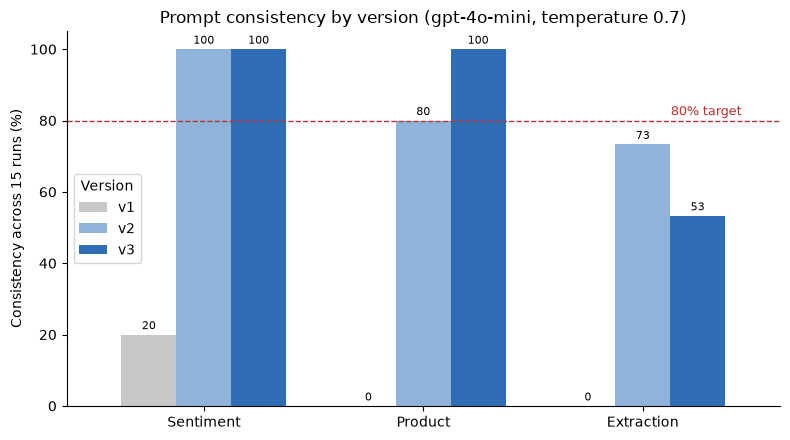

In [28]:
# Chart: consistency per version
pivot = comparison.pivot(index="Task", columns="Version", values="Consistency %").loc[["Sentiment", "Product", "Extraction"]]
ax = pivot.plot(kind="bar", figsize=(8, 4.5), color=["#c8c8c8", "#8fb3d9", "#2f6db5"], rot=0, width=0.75)
ax.axhline(80, ls="--", color="#b33", lw=1)
ax.text(2.45, 81.5, "80% target", color="#b33", ha="right", fontsize=9)
ax.set_ylim(0, 105)
ax.set_ylabel("Consistency across 15 runs (%)")
ax.set_xlabel("")
ax.set_title("Prompt consistency by version (gpt-4o-mini, temperature 0.7)")
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", fontsize=8, padding=2)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "consistency_by_version.png", dpi=150)
plt.show()

# Raw data saver

In [29]:
(RESULTS_DIR / "all_runs.json").write_text(json.dumps(ALL_RUNS, indent=2, ensure_ascii=False))
comparison.to_csv(RESULTS_DIR / "final_comparison.csv", index=False)
runs_table().to_csv(RESULTS_DIR / "all_metrics.csv", index=False)


def md_table(df):
    cols = list(df.columns)
    lines = ["| " + " | ".join(map(str, cols)) + " |", "|" + "---|" * len(cols)]
    lines += ["| " + " | ".join(str(v) for v in row) + " |" for row in df.itertuples(index=False)]
    return "\n".join(lines)


diag_rows = []
for task in ["Sentiment", "Product", "Extraction"]:
    for n in (5, 10, 15):
        r = [x for x in ALL_RUNS if x["task"] == task and x["version"] == "v1" and x["label"] == "diagnosis" and x["n"] == n][-1]
        diag_rows.append({"Task": task, "Runs": n, "Unique outputs": r["metrics"]["unique_outputs"],
                          "Consistency %": r["metrics"]["consistency_%"]})

report = ["# Failure Analysis Report — TechFlow Solutions prompts", "",
          f"Model `{MODEL}`, temperature {TEMPERATURE} for every run. Generated by `prompt_engineering_lab.ipynb`; "
          "raw responses are in `results/all_runs.json`.", "",
          "## How consistency is measured", "",
          "- **Sentiment:** share of runs returning the most common output exactly.",
          "- **Extraction:** share of runs whose parsed JSON equals the most common parsed JSON (unparseable = miss).",
          "- **Product description:** share of runs meeting the full spec (headline, exactly 3 features, "
          f"{LEN_MIN}–{LEN_MAX} words, correct price, no invented numbers).", "",
          "## Consistency by version (15 runs each)", "", md_table(comparison), "",
          "## v1 → v3 improvement (percentage points)", "", md_table(improvement.reset_index()), "",
          "![Consistency by version](results/consistency_by_version.png)", "",
          "## v1 diagnosis at 5 / 10 / 15 runs", "", md_table(pd.DataFrame(diag_rows)), "",
          "## Documented failure patterns (v1)", ""]
for task, patterns in FAILURE_PATTERNS.items():
    report.append(f"### {task}")
    report += [f"- **{p}.** {e}" for p, e in patterns]
    report.append("")
report += ["## Task variations (Step 12)", "", "### Sentiment (5 runs per message)", "",
           md_table(sentiment_var.drop(columns=["message"])), "",
           "### Extraction (5 runs per feedback)", "",
           md_table(extraction_var.drop(columns=["v3 sample"])), ""]

Path("failure_analysis_report.md").write_text("\n".join(report), encoding="utf-8")
print("✅ Wrote failure_analysis_report.md and results/ (all_runs.json, all_metrics.csv, final_comparison.csv, chart)")
print(f"Total API calls made: {sum(r['n'] for r in ALL_RUNS)}")

✅ Wrote failure_analysis_report.md and results/ (all_runs.json, all_metrics.csv, final_comparison.csv, chart)
Total API calls made: 360
